<a href="https://colab.research.google.com/github/Mahendra-69/CSL701-CS09_Machine-Learning-Lab/blob/main/Expriments/ML_Experiment_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###  ML Experiment Number 9
Student Name :Mahendra R. Choudhari

Batch :CS1


Roll Number :CS09



### **Aim**

To implement Classification and Regression Trees (CART) using Python on the Palmer Penguins Dataset Extended.

## Objectives

1. To understand the concept and working of the CART algorithm.
2. To implement Decision Tree Classification using Python.   
3. To visualize the constructed Decision Tree structure and decision boundaries.   
4. To analyze impurity measures such as Gini Index and Entropy.
5. To compare the decision boundary of a Decision Tree with a linear classification boundary (e.g., Logistic Regression).   
6. To evaluate and compare the performance of both classifiers.

# Relevant Theory

###Classification and Regression Trees (CART)
CART is a non-parametric supervised machine learning algorithm used for both classification and regression tasks. It builds a binary decision tree by recursively splitting the dataset based on feature values that maximize information gain or minimize impurity.

A tree consists of:

* Root Node: The topmost node representing the entire dataset.

* Internal Nodes: Decision points based on feature splits.

* Leaf/Terminal Nodes: Output class labels or predictions.

Impurity MeasuresGini Index (Gini Impurity): Measures the frequency with which a randomly chosen element from the set would be incorrectly labeled.$$Gini(D) = 1 - \sum_{i=1}^{k} p_i^2$$where $p_i$ is the probability of an item belonging to class $i$.Entropy & Information Gain: Measures the amount of impurity or randomness in the data.$$Entropy(D) = -\sum_{i=1}^{k} p_i \log_2(p_i)$$Dataset InformationGet the Palmer Penguins Dataset Extended from Kaggle using the following link:https://www.kaggle.com/datasets/samybaladram/palmers-penguin-dataset-extendedThe Palmer Penguins dataset contains measurements of penguin species across islands in the Palmer Archipelago:AdelieChinstrapGentooThe primary numerical features are:culmen_length_mm (or bill_length_mm)culmen_depth_mm (or bill_depth_mm)flipper_length_mmbody_mass_gFor visualization, we will use: culmen_length_mm and flipper_length_mm.

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Palmer Penguins Extended dataset.
---

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

df = pd.read_csv('/content/palmerpenguins_extended.csv')

print("First 5 rows of the dataset:")
print(df.head())

print("\nDataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nColumn Names:")
print(df.columns.tolist())


First 5 rows of the dataset:
  species  island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Biscoe            53.4           17.8              219.0   
1  Adelie  Biscoe            49.3           18.1              245.0   
2  Adelie  Biscoe            55.7           16.6              226.0   
3  Adelie  Biscoe            38.0           15.6              221.0   
4  Adelie  Biscoe            60.7           17.9              177.0   

   body_mass_g     sex  diet life_stage health_metrics  year  
0       5687.0  female  fish      adult     overweight  2021  
1       6811.0  female  fish      adult     overweight  2021  
2       5388.0  female  fish      adult     overweight  2021  
3       6262.0  female  fish      adult     overweight  2021  
4       4811.0  female  fish   juvenile     overweight  2021  

Dataset Shape: (3430, 11)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3430 entries, 0 to 3429
Data columns (total 11 columns):
 #   Colum

# Task 2: Select Features and Target & Preprocess

* Handle missing values (e.g., drop rows with missing values or impute with median).   
* Select features ($X$) such as culmen_length_mm, culmen_depth_mm, flipper_length_mm, body_mass_g and set species as the target label ($y$).   
* Encode categorical targets if necessary using LabelEncoder.

In [2]:

# Check missing values
print("Missing Values Before Preprocessing:")
print(df.isnull().sum())

# Handle missing values
df = df.dropna().copy()

# Select features
X = df[
    ['bill_length_mm', 'bill_depth_mm',
     'flipper_length_mm', 'body_mass_g']
]

# Select target
y = df['species']

# Encode target labels
le = LabelEncoder()
y_encoded = le.fit_transform(y)

print("\nFeatures Shape:", X.shape)
print("Target Shape:", y_encoded.shape)

print("\nSpecies Classes:")
print(le.classes_)

print("\nEncoded Species (first 10 rows):")
print(y_encoded[:10])

print("\nMissing Values After Preprocessing:")
print(df.isnull().sum())


Missing Values Before Preprocessing:
species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
diet                 0
life_stage           0
health_metrics       0
year                 0
dtype: int64

Features Shape: (3430, 4)
Target Shape: (3430,)

Species Classes:
['Adelie' 'Chinstrap' 'Gentoo']

Encoded Species (first 10 rows):
[0 0 0 0 0 0 0 0 0 0]

Missing Values After Preprocessing:
species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
diet                 0
life_stage           0
health_metrics       0
year                 0
dtype: int64


# Task 3: Split the Data

* Divide the dataset into training and testing sets using train_test_split.

In [3]:

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.2,
    random_state=42
)

print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)

print("\nTraining Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))


Training Features Shape: (2744, 4)
Testing Features Shape: (686, 4)

Training Target Shape: (2744,)
Testing Target Shape: (686,)

Training Samples: 2744
Testing Samples: 686


# Task 4: Implement CART Classifier

* Create a DecisionTreeClassifier model using the Gini criterion (or Entropy).   
* Fit the model on the training data and make predictions on the test set.   

In [4]:

# Create the CART Decision Tree Classifier
cart_model = DecisionTreeClassifier(
    criterion='gini',
    random_state=42
)

# Train the model
cart_model.fit(X_train, y_train)

# Make predictions on test data
y_pred_cart = cart_model.predict(X_test)

print("CART Classifier trained successfully!")

print("\nFirst 10 Actual Labels:")
print(y_test[:10])

print("\nFirst 10 Predicted Labels:")
print(y_pred_cart[:10])

print("\nNumber of Predictions:", len(y_pred_cart))


CART Classifier trained successfully!

First 10 Actual Labels:
[1 0 2 0 1 0 0 2 1 2]

First 10 Predicted Labels:
[0 2 0 0 2 2 2 2 0 2]

Number of Predictions: 686


# Task 5: Evaluate CART Model

* Accuracy: Calculate classification accuracy.   
* Confusion Matrix: Generate the matrix to analyze misclassifications across species.
* Classification Report: Output Precision, Recall, F1-Score, and Support.   

In [5]:

# Calculate accuracy
cart_accuracy = accuracy_score(y_test, y_pred_cart)

print("CART Model Accuracy:", round(cart_accuracy, 4))
print("CART Model Accuracy (%):", round(cart_accuracy * 100, 2), "%")

# Generate confusion matrix
cart_cm = confusion_matrix(y_test, y_pred_cart)

print("\nConfusion Matrix:")
print(cart_cm)

# Generate classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_cart,
    target_names=le.classes_
))


CART Model Accuracy: 0.4519
CART Model Accuracy (%): 45.19 %

Confusion Matrix:
[[164  67  73]
 [ 61  27  37]
 [ 89  49 119]]

Classification Report:
              precision    recall  f1-score   support

      Adelie       0.52      0.54      0.53       304
   Chinstrap       0.19      0.22      0.20       125
      Gentoo       0.52      0.46      0.49       257

    accuracy                           0.45       686
   macro avg       0.41      0.41      0.41       686
weighted avg       0.46      0.45      0.46       686



# Task 6: Visualize Decision Tree & Decision Boundary

* Visualize Tree Structure: Plot the decision tree diagram using sklearn.tree.plot_tree.
* Select 2-D Features: Select culmen_length_mm and flipper_length_mm.   
* Train 2-D Model & Plot Boundary: Train the decision tree on 2D data and plot axis-aligned rectangular decision boundaries along with data points


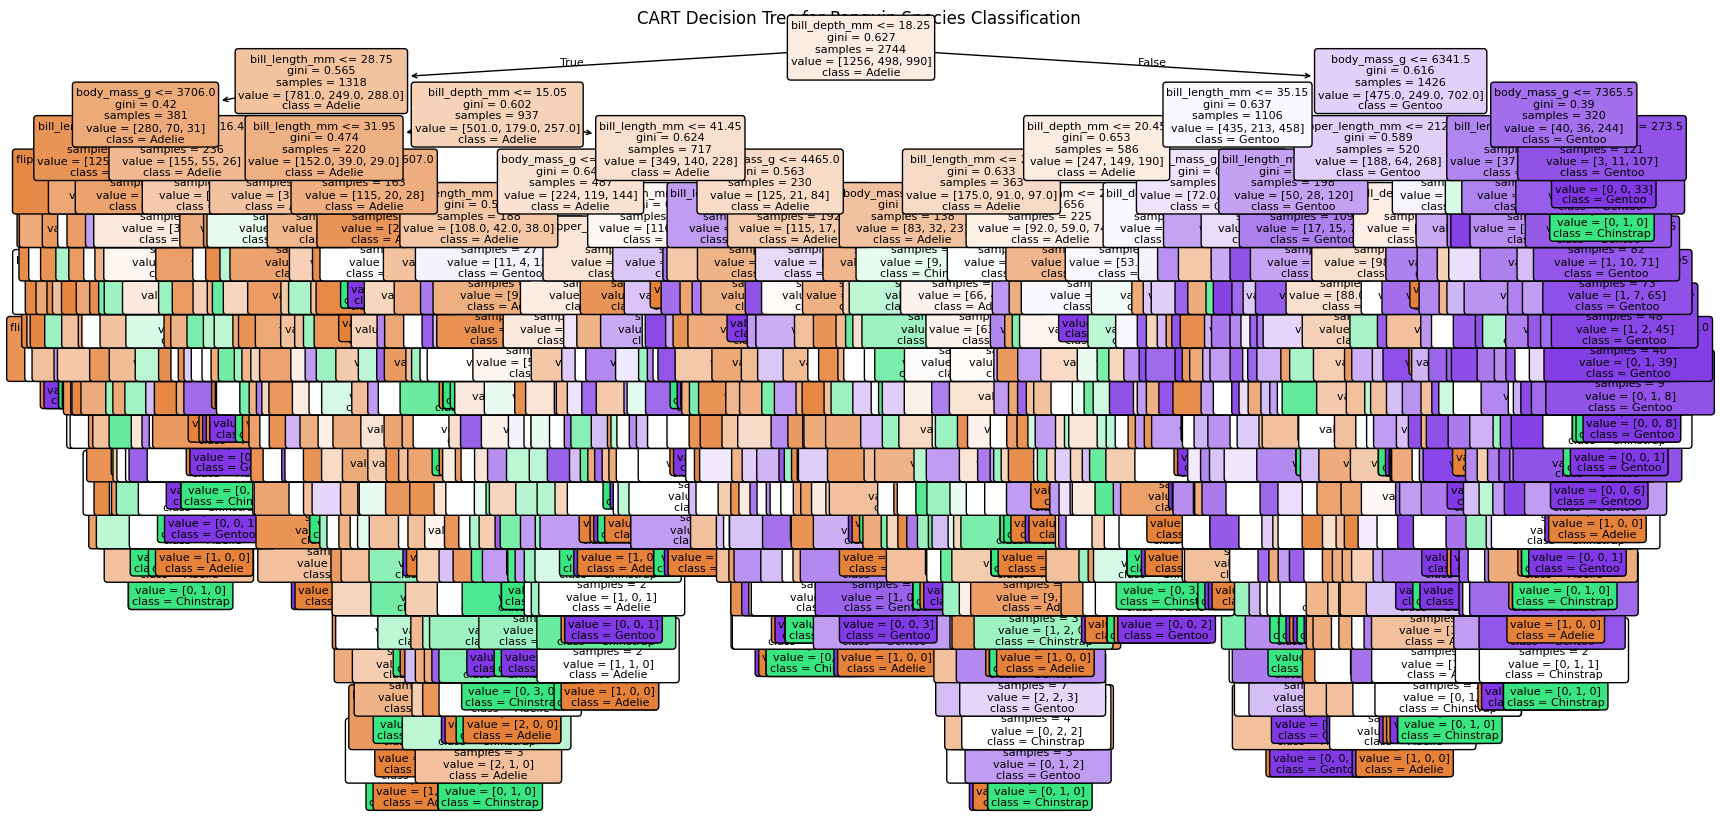

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


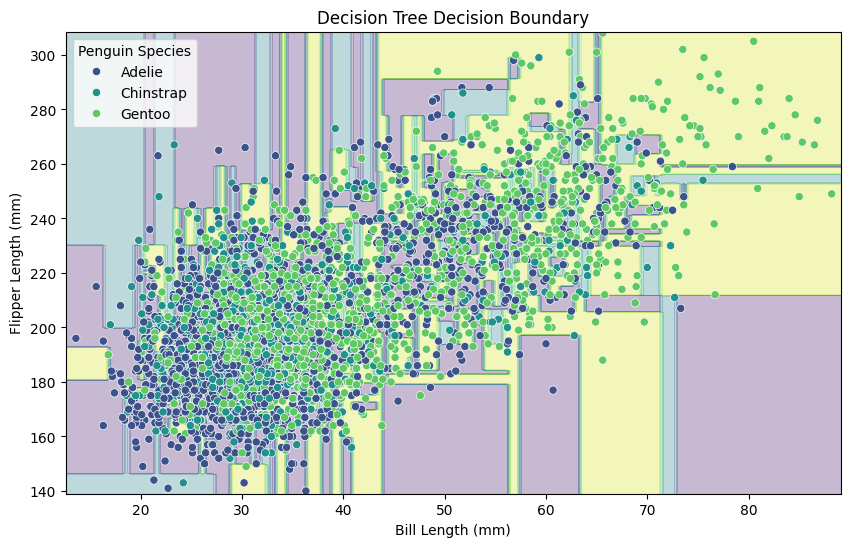

In [6]:

# Part 1: Visualize the CART Decision Tree
plt.figure(figsize=(20, 10))

plot_tree(
    cart_model,
    feature_names=X.columns,
    class_names=le.classes_,
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("CART Decision Tree for Penguin Species Classification")
plt.show()


# Part 2: Select two features for decision boundary visualization
X_2d = df[['bill_length_mm', 'flipper_length_mm']]
y_2d = le.transform(df['species'])

# Split the 2D data
X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d,
    y_2d,
    test_size=0.2,
    random_state=42
)

# Train a Decision Tree using two features
cart_2d = DecisionTreeClassifier(
    criterion='gini',
    random_state=42
)

cart_2d.fit(X_train_2d, y_train_2d)

# Create a mesh grid for plotting decision boundaries
x_min, x_max = X_2d.iloc[:, 0].min() - 1, X_2d.iloc[:, 0].max() + 1
y_min, y_max = X_2d.iloc[:, 1].min() - 1, X_2d.iloc[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.5),
    np.arange(y_min, y_max, 0.5)
)

Z = cart_2d.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot decision boundaries
plt.figure(figsize=(10, 6))

plt.contourf(xx, yy, Z, alpha=0.3, cmap='viridis')

sns.scatterplot(
    x=X_2d['bill_length_mm'],
    y=X_2d['flipper_length_mm'],
    hue=df['species'],
    palette='viridis',
    s=35
)

plt.title("Decision Tree Decision Boundary")
plt.xlabel("Bill Length (mm)")
plt.ylabel("Flipper Length (mm)")
plt.legend(title="Penguin Species")
plt.show()


# Task 7: Normal Linear Classification Boundary

* Train a Logistic Regression model using the same two features as a normal linear baseline.   
* Visualize its linear decision boundary.

Logistic Regression model trained successfully!

First 10 Actual Labels:
[1 0 2 0 1 0 0 2 1 2]

First 10 Predicted Labels:
[0 0 0 0 2 0 0 2 0 2]

Logistic Regression Accuracy: 0.5073
Logistic Regression Accuracy (%): 50.73 %


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


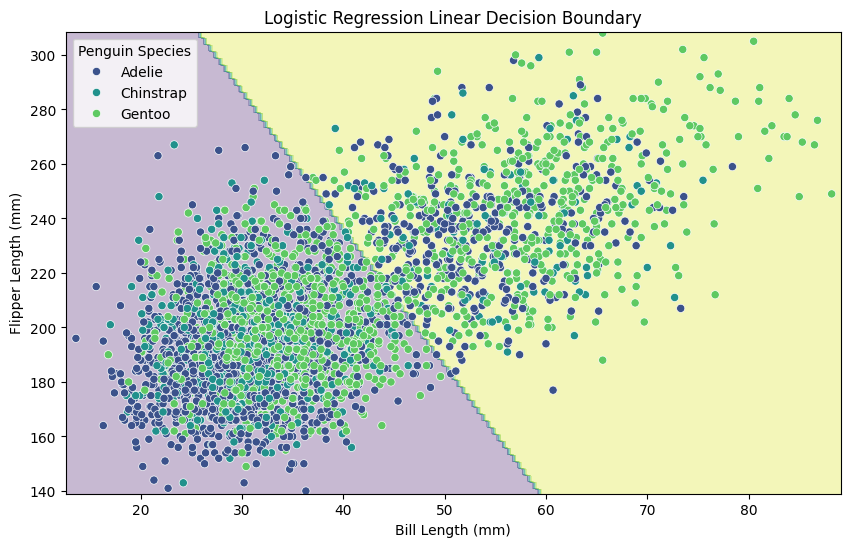

In [7]:

# Create Logistic Regression model using two features
lr_model = LogisticRegression(max_iter=1000)

# Train the model
lr_model.fit(X_train_2d, y_train_2d)

# Make predictions
y_pred_lr = lr_model.predict(X_test_2d)

print("Logistic Regression model trained successfully!")

print("\nFirst 10 Actual Labels:")
print(y_test_2d[:10])

print("\nFirst 10 Predicted Labels:")
print(y_pred_lr[:10])

# Calculate accuracy
lr_accuracy = accuracy_score(y_test_2d, y_pred_lr)

print("\nLogistic Regression Accuracy:", round(lr_accuracy, 4))
print("Logistic Regression Accuracy (%):", round(lr_accuracy * 100, 2), "%")

# Plot linear decision boundary
x_min, x_max = X_2d.iloc[:, 0].min() - 1, X_2d.iloc[:, 0].max() + 1
y_min, y_max = X_2d.iloc[:, 1].min() - 1, X_2d.iloc[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.5),
    np.arange(y_min, y_max, 0.5)
)

Z = lr_model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(10, 6))

plt.contourf(xx, yy, Z, alpha=0.3, cmap='viridis')

sns.scatterplot(
    x=X_2d['bill_length_mm'],
    y=X_2d['flipper_length_mm'],
    hue=df['species'],
    palette='viridis',
    s=35
)

plt.title("Logistic Regression Linear Decision Boundary")
plt.xlabel("Bill Length (mm)")
plt.ylabel("Flipper Length (mm)")
plt.legend(title="Penguin Species")
plt.show()


# Task 8: Compare CART and Normal Linear Boundary

* Plot both the Decision Tree (axis-aligned non-linear) and Logistic Regression (linear) decision boundaries on side-by-side subplots.   * Compare how non-linear CART boundaries differ from straight linear hyperplanes.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


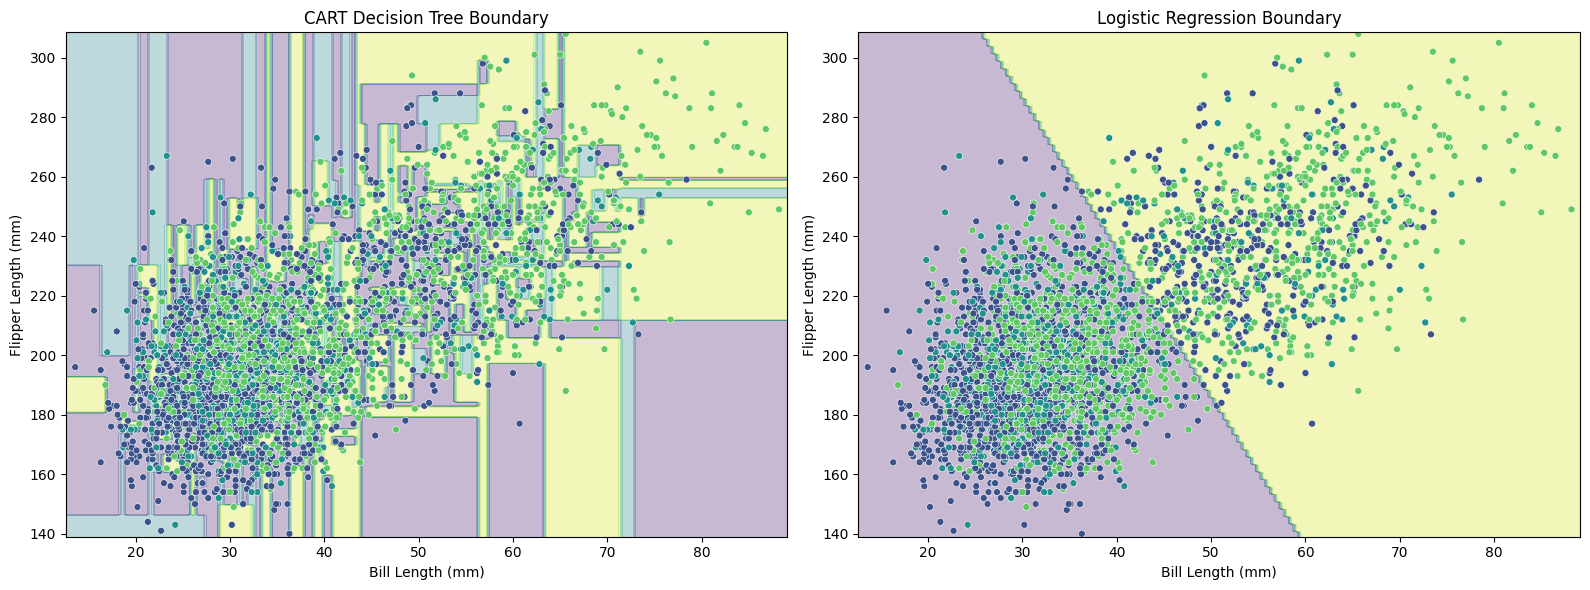

In [8]:

# Create side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Create mesh grid
x_min, x_max = X_2d.iloc[:, 0].min() - 1, X_2d.iloc[:, 0].max() + 1
y_min, y_max = X_2d.iloc[:, 1].min() - 1, X_2d.iloc[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.5),
    np.arange(y_min, y_max, 0.5)
)

grid = np.c_[xx.ravel(), yy.ravel()]

# CART decision boundary
Z_cart = cart_2d.predict(grid).reshape(xx.shape)

axes[0].contourf(xx, yy, Z_cart, alpha=0.3, cmap='viridis')
sns.scatterplot(
    data=df,
    x='bill_length_mm',
    y='flipper_length_mm',
    hue='species',
    palette='viridis',
    s=25,
    ax=axes[0],
    legend=False
)
axes[0].set_title("CART Decision Tree Boundary")
axes[0].set_xlabel("Bill Length (mm)")
axes[0].set_ylabel("Flipper Length (mm)")

# Logistic Regression decision boundary
Z_lr = lr_model.predict(grid).reshape(xx.shape)

axes[1].contourf(xx, yy, Z_lr, alpha=0.3, cmap='viridis')
sns.scatterplot(
    data=df,
    x='bill_length_mm',
    y='flipper_length_mm',
    hue='species',
    palette='viridis',
    s=25,
    ax=axes[1],
    legend=False
)
axes[1].set_title("Logistic Regression Boundary")
axes[1].set_xlabel("Bill Length (mm)")
axes[1].set_ylabel("Flipper Length (mm)")

plt.tight_layout()
plt.show()


# Task 9: Compare Performance

* Compare the evaluation metrics (Accuracy, Confusion Matrix, Classification Report) of the CART Classifier vs. Logistic Regression.

In [9]:

# Evaluate CART Classifier
y_pred_cart_2d = cart_2d.predict(X_test_2d)

print("========== CART CLASSIFIER ==========")
print("Accuracy:", round(accuracy_score(y_test_2d, y_pred_cart_2d), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_2d, y_pred_cart_2d))

print("\nClassification Report:")
print(classification_report(
    y_test_2d,
    y_pred_cart_2d,
    target_names=le.classes_
))


# Evaluate Logistic Regression
print("\n========== LOGISTIC REGRESSION ==========")
print("Accuracy:", round(accuracy_score(y_test_2d, y_pred_lr), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_2d, y_pred_lr))

print("\nClassification Report:")
print(classification_report(
    y_test_2d,
    y_pred_lr,
    target_names=le.classes_
))


# Compare model accuracies
print("\n========== ACCURACY COMPARISON ==========")
print("CART Accuracy:", round(accuracy_score(y_test_2d, y_pred_cart_2d) * 100, 2), "%")
print("Logistic Regression Accuracy:", round(accuracy_score(y_test_2d, y_pred_lr) * 100, 2), "%")


========== CART CLASSIFIER ==========
Accuracy: 0.4052

Confusion Matrix:
[[153  63  88]
 [ 53  29  43]
 [121  40  96]]

Classification Report:
              precision    recall  f1-score   support

      Adelie       0.47      0.50      0.48       304
   Chinstrap       0.22      0.23      0.23       125
      Gentoo       0.42      0.37      0.40       257

    accuracy                           0.41       686
   macro avg       0.37      0.37      0.37       686
weighted avg       0.41      0.41      0.40       686


========== LOGISTIC REGRESSION ==========
Accuracy: 0.5073

Confusion Matrix:
[[245   0  59]
 [104   0  21]
 [154   0 103]]

Classification Report:
              precision    recall  f1-score   support

      Adelie       0.49      0.81      0.61       304
   Chinstrap       0.00      0.00      0.00       125
      Gentoo       0.56      0.40      0.47       257

    accuracy                           0.51       686
   macro avg       0.35      0.40      0.36       686


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


# Conclusion

The experiment successfully demonstrated the implementation of the Classification and Regression Tree (CART) algorithm using the Palmer Penguins Extended dataset. The dataset was preprocessed to handle missing values before training. The decision tree structure was visualized, showcasing the hierarchical splits based on feature thresholds. A comparison with a normal linear boundary (Logistic Regression) highlighted CART's ability to create non-linear, axis-aligned decision boundaries to separate different penguin species.